In [7]:
from data_pipeline.LIDAR_segmentation import ransac_plane, segment_planes
import laspy
import numpy as np
import open3d as o3d

path = "data/sample_roofdata_50"

las = laspy.read(path + "/182221864.laz")

points = np.column_stack([
    las.x,
    las.y,
    las.z
])

indices = ransac_plane(points)[0]

plane_points = points[indices]

In [ ]:
pcd_o3d = o3d.geometry.PointCloud()
pcd_o3d.points = o3d.utility.Vector3dVector(plane_points)

pcd_center = pcd_o3d.get_center()

pcd_o3d.translate(-pcd_center)

o3d.visualization.draw_geometries([pcd_o3d])

RuntimeError: Unable to cast Python instance of type <class 'numpy.ndarray'> to C++ type '?' (#define PYBIND11_DETAILED_ERROR_MESSAGES or compile in debug mode for details)

: 

In [8]:
planes = segment_planes(points)
print(planes)

[{'points': array([[5.71822480e+05, 7.03383757e+06, 9.38100000e+01],
       [5.71823980e+05, 7.03383815e+06, 9.41400000e+01],
       [5.71823790e+05, 7.03383776e+06, 9.38900000e+01],
       ...,
       [5.71832300e+05, 7.03384267e+06, 9.67800000e+01],
       [5.71839580e+05, 7.03384323e+06, 9.68400000e+01],
       [5.71830700e+05, 7.03384271e+06, 9.68900000e+01]], shape=(1380, 3)), 'indices': array([   0,    1,    2, ..., 2745, 2920, 3102], shape=(1380,)), 'plane': array([-2.80106816e-02,  5.58525686e-01, -8.29014150e-01, -3.91248407e+06]), 'rmse': 0.04333065577174245}, {'points': array([[5.71841580e+05, 7.03384486e+06, 9.56000000e+01],
       [5.71843010e+05, 7.03384640e+06, 9.45900000e+01],
       [5.71841730e+05, 7.03384487e+06, 9.56100000e+01],
       ...,
       [5.71822980e+05, 7.03384634e+06, 9.42300000e+01],
       [5.71822430e+05, 7.03384724e+06, 9.34300000e+01],
       [5.71821850e+05, 7.03384707e+06, 9.36400000e+01]], shape=(1197, 3)), 'indices': array([1340, 1357, 1502, ...

In [9]:
planes = [plane["plane"] for plane in planes]

print(planes)

[array([-2.80106816e-02,  5.58525686e-01, -8.29014150e-01, -3.91248407e+06]), array([-2.78561478e-02,  5.59103393e-01,  8.28629851e-01, -3.91679654e+06]), array([ 5.61758065e-01,  2.87150748e-02, -8.26803073e-01, -5.23125545e+05]), array([-5.70439309e-01, -2.82688256e-02, -8.20853134e-01,  5.25117999e+05])]


In [8]:
plane_points = points  # preserve the list of separate planes

all_points = np.concatenate(plane_points, axis=0)
all_points = np.ascontiguousarray(all_points, dtype=np.float64)

print(all_points.shape, all_points.dtype)

pcd_o3d = o3d.geometry.PointCloud()
pcd_o3d.points = o3d.utility.Vector3dVector(all_points)

pcd_center = pcd_o3d.get_center()

pcd_o3d.translate(-pcd_center)

o3d.visualization.draw_geometries([pcd_o3d])

(1400, 3) float64


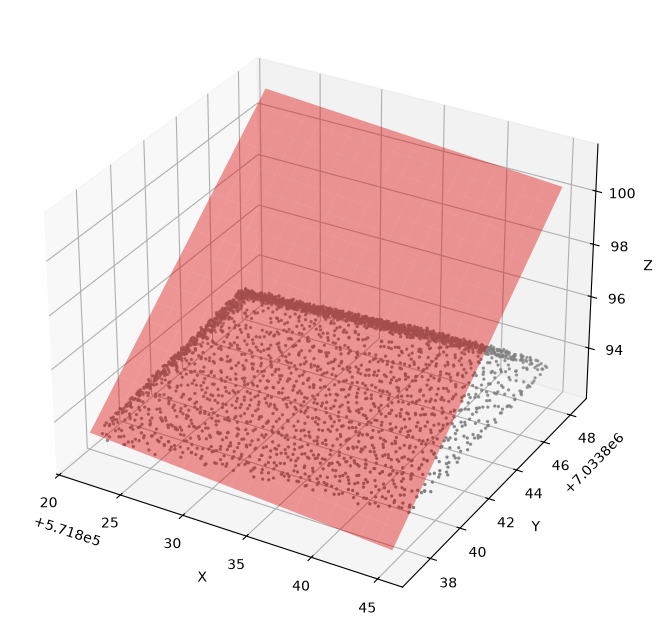

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

a, b, c, d = planes[0]

x = np.linspace(points[:, 0].min(), points[:, 0].max(), 20)
y = np.linspace(points[:, 1].min(), points[:, 1].max(), 20)

X, Y = np.meshgrid(x, y)
Z = (-a * X - b * Y - d) / c

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    s=2,
    color="gray"
)

ax.plot_surface(
    X, Y, Z,
    color="red",
    alpha=0.4
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

In [ ]:
import numpy as np
import open3d as o3d

points = np.asarray(points, dtype=np.float64)
a, b, c, d = planes[0]

# Create point cloud
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)
pcd.paint_uniform_color([0.5, 0.5, 0.5])

# Normal vector of ax + by + cz + d = 0
normal = np.array([a, b, c], dtype=np.float64)
normal /= np.linalg.norm(normal)

# A point lying on the plane
plane_origin = -d * np.array([a, b, c]) / (a*a + b*b + c*c)

# Create two perpendicular directions within the plane
helper = np.array([0.0, 0.0, 1.0])

if abs(np.dot(normal, helper)) > 0.9:
    helper = np.array([0.0, 1.0, 0.0])

u_axis = np.cross(normal, helper)
u_axis /= np.linalg.norm(u_axis)

v_axis = np.cross(normal, u_axis)
v_axis /= np.linalg.norm(v_axis)

# Project point-cloud positions onto the plane coordinate system
relative = points - plane_origin
u_coordinates = relative @ u_axis
v_coordinates = relative @ v_axis

u_min, u_max = u_coordinates.min(), u_coordinates.max()
v_min, v_max = v_coordinates.min(), v_coordinates.max()

# Four corners of the plane
vertices = np.array([
    plane_origin + u_min * u_axis + v_min * v_axis,
    plane_origin + u_max * u_axis + v_min * v_axis,
    plane_origin + u_max * u_axis + v_max * v_axis,
    plane_origin + u_min * u_axis + v_max * v_axis
])

# Two triangles form the rectangular surface
triangles = np.array([
    [0, 1, 2],
    [0, 2, 3]
], dtype=np.int32)

plane_mesh = o3d.geometry.TriangleMesh(
    vertices=o3d.utility.Vector3dVector(vertices),
    triangles=o3d.utility.Vector3iVector(triangles)
)

plane_mesh.paint_uniform_color([1.0, 0.0, 0.0])
plane_mesh.compute_vertex_normals()

o3d.visualization.draw_geometries(
    [pcd, plane_mesh],
    window_name="Point cloud and fitted plane",
    width=1000,
    height=800,
    mesh_show_back_face=True
)

: 